# Controle fuzzy de reservatório com duas entradas e quatro comportas

Notebook autocontido para o **Google Colab**: execute as células em ordem. Não é necessário enviar arquivos `.py`, montar o Google Drive ou utilizar GPU.

| Tipo | Variáveis | Unidade |
|---|---|---|
| Entrada 1 | Nível de água do reservatório | m |
| Entrada 2 | Vazão afluente | m³/s |
| Saídas 1 a 4 | Aberturas solicitadas às comportas G1, G2, G3 e G4 | % |

Cada saída é calculada por inferência **Mamdani**, com categorias **baixa, média e alta**, operadores mínimo/máximo e **centroide**. As quatro matrizes de consequentes são diferentes. Em certas condições, duas ou mais comportas podem receber comandos iguais; no equilíbrio nominal, todas recebem 50%.

O reservatório é didático. A versão usa quatro comportas de 75 m³/s cada a 10 m de carga, preservando a capacidade total de 300 m³/s do modelo anterior. A vazão turbinada permanece em 100 m³/s. Os resultados deste notebook pertencem à versão de quatro comportas e não devem ser substituídos pelos resultados do artigo de uma comporta.

Para importar, utilize a opção de upload de notebook do Colab. [Documentação oficial](https://research.google.com/colaboratory/faq.html).

In [1]:
# Instala somente bibliotecas ausentes; não altera versões já disponíveis no Colab.
import importlib.util
import subprocess
import sys

dependencias = {"numpy": "numpy>=1.26,<3", "matplotlib": "matplotlib>=3.8,<4"}
ausentes = [requisito for modulo, requisito in dependencias.items()
            if importlib.util.find_spec(modulo) is None]
if ausentes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *ausentes])

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import json
from pathlib import Path

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False})
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.12.14 | NumPy 2.5.4 | Matplotlib 3.11.2


## Núcleo do sistema

O código abaixo contém o controlador, o modelo, a simulação, a exportação e as verificações. Ele também é fornecido como um arquivo Python independente.

As duas entradas físicas são nível e afluência. A largura das pertinências e o número de pontos do centroide são parâmetros de configuração.

Para cada comporta $j$, as regras são agregadas separadamente e o comando é

$$u_j = \frac{\int_0^1 u\,\mu_j(u)\,du}{\int_0^1 \mu_j(u)\,du}.$$

A integração usa 401 pontos por padrão. A função `controlar(nivel_m, vazao_m3_s)` devolve um dicionário com quatro percentuais. A classe `ControladorFuzzy` evita reconstruir as funções de saída a cada amostra.

In [2]:
"""Controle fuzzy Mamdani com duas entradas e quatro comportas.

Python >= 3.10; NumPy >= 1.26. Nenhum arquivo externo e nenhum acesso de rede
são necessários. Matplotlib é opcional, importado somente ao criar gráficos.

Exemplo de uso em Google Colab ou Python:
    controlar(nivel_m=10.0, vazao_m3_s=350.0)

Todas as grandezas e regras são didáticas, sem calibração em uma usina real.
"""
from __future__ import annotations

import argparse
import csv
import json
import math
import numbers
import platform
from pathlib import Path
from typing import Any

import numpy as np

CATEGORIAS = ("baixa", "media", "alta")
COMPORTAS = ("G1", "G2", "G3", "G4")
# Eixos: categoria do nível, categoria da vazão afluente, comporta.
# 0 = baixa, 1 = média, 2 = alta.
BASE_REGRAS = np.array([
    [[0, 0, 0, 0], [1, 0, 0, 0], [2, 2, 0, 0]],
    [[1, 0, 0, 0], [1, 1, 1, 1], [2, 2, 2, 1]],
    [[2, 2, 0, 0], [2, 2, 2, 1], [2, 2, 2, 2]],
], dtype=int)

CONFIGURACAO = {
    "area_reservatorio_m2": 100_000.0,
    "nivel_referencia_m": 10.0,
    "nivel_inicial_m": 9.0,
    "abertura_inicial_fracao": 0.5,
    "vazao_turbinada_m3_s": 100.0,
    "capacidade_por_comporta_m3_s_em_10m": 75.0,
    "capacidade_total_m3_s_em_10m": 300.0,
    "constante_tempo_atuador_s": 120.0,
    "periodo_controle_s": 60.0,
    "horizonte_s": 86400.0,
    "faixa_didatica_nivel_m": [9.0, 11.0],
    "dominio_api_nivel_m": [0.0, 30.0],
    "dominio_api_vazao_m3_s": [0.0, 1000.0],
}


def _real_finito(nome: str, valor: Any, minimo: float, maximo: float) -> float:
    if isinstance(valor, (bool, np.bool_)) or not isinstance(valor, numbers.Real):
        raise ValueError(f"{nome} deve ser um número real.")
    valor = float(valor)
    if not math.isfinite(valor) or not minimo <= valor <= maximo:
        raise ValueError(f"{nome} deve estar entre {minimo:g} e {maximo:g}, sem NaN ou infinito.")
    return valor


def _validar_pontos(pontos: int) -> int:
    if isinstance(pontos, (bool, np.bool_)) or not isinstance(pontos, numbers.Integral):
        raise ValueError("pontos_centroide deve ser inteiro.")
    if not 51 <= int(pontos) <= 10001:
        raise ValueError("pontos_centroide deve estar entre 51 e 10001.")
    return int(pontos)


def _integral_trapezios(y: np.ndarray, x: np.ndarray, axis: int = -1) -> np.ndarray:
    """NumPy 1.26 usa trapz; NumPy 2.x usa trapezoid quando disponível."""
    integrador = getattr(np, "trapezoid", None)
    if integrador is not None:
        return integrador(y, x=x, axis=axis)
    return np.trapz(y, x=x, axis=axis)


def pertinencias_entrada(x_normalizado: float) -> np.ndarray:
    """Retorna [baixa, média, alta], com ombros e recorte de x em [-1,1]."""
    x = _real_finito("x_normalizado", x_normalizado, -1e12, 1e12)
    x = np.clip(x, -1.0, 1.0)
    return np.maximum(0.0, 1.0 - np.abs(np.array([-1.0, 0.0, 1.0]) - x))


def _triangular(x: np.ndarray, a: float, b: float, c: float) -> np.ndarray:
    subida = np.ones_like(x) if a == b else (x - a) / (b - a)
    descida = np.ones_like(x) if b == c else (c - x) / (c - b)
    return np.maximum(0.0, np.minimum(1.0, np.minimum(subida, descida)))


def funcoes_saida(pontos: int = 401) -> tuple[np.ndarray, np.ndarray]:
    """Universo [0,1] e pertinências baixa/média/alta, em matriz (3,pontos)."""
    pontos = _validar_pontos(pontos)
    universo = np.linspace(0.0, 1.0, pontos)
    pertinencias = np.array([
        _triangular(universo, 0.0, 0.0, 0.4),
        _triangular(universo, 0.2, 0.5, 0.8),
        _triangular(universo, 0.6, 1.0, 1.0),
    ])
    return universo, pertinencias


class ControladorFuzzy:
    """Mamdani com nove regras de quatro consequentes e quatro centroides."""

    def __init__(self, largura_nivel_m: float = 1.0, pontos_centroide: int = 401):
        self.largura_nivel_m = _real_finito("largura_nivel_m", largura_nivel_m, 1e-6, 10.0)
        self.universo, self.consequentes = funcoes_saida(pontos_centroide)

    def inferir(self, nivel_m: float, vazao_m3_s: float) -> np.ndarray:
        """Retorna quatro frações de abertura, na ordem G1, G2, G3, G4."""
        h = _real_finito("nivel_m", nivel_m, 0.0, 30.0)
        qa = _real_finito("vazao_m3_s", vazao_m3_s, 0.0, 1000.0)
        mh = pertinencias_entrada((h - 10.0) / self.largura_nivel_m)
        mq = pertinencias_entrada((qa - 250.0) / 100.0)
        ativacoes = np.minimum(mh[:, None], mq[None, :])
        agregadas = np.empty((4, self.universo.size), dtype=float)
        for comporta in range(4):
            # Cada comporta tem consequentes e agregação próprios.
            alturas = np.array([
                ativacoes[BASE_REGRAS[:, :, comporta] == categoria].max()
                for categoria in range(3)
            ])
            agregadas[comporta] = np.minimum(alturas[:, None], self.consequentes).max(axis=0)
        areas = _integral_trapezios(agregadas, self.universo, axis=1)
        if np.any(areas <= 0):
            raise RuntimeError("Alguma saída fuzzy ficou sem área de pertinência.")
        centroides = _integral_trapezios(agregadas * self.universo, self.universo, axis=1) / areas
        if not np.all(np.isfinite(centroides)) or np.any((centroides < 0) | (centroides > 1)):
            raise RuntimeError("O centroide produziu abertura inválida.")
        return centroides


def inferir_aberturas(nivel_m: float, vazao_m3_s: float,
                     largura_nivel_m: float = 1.0,
                     pontos_centroide: int = 401) -> np.ndarray:
    """Interface em frações [0,1]. Para muitas chamadas, reutilize a classe."""
    return ControladorFuzzy(largura_nivel_m, pontos_centroide).inferir(nivel_m, vazao_m3_s)


def controlar(nivel_m: float, vazao_m3_s: float,
              largura_nivel_m: float = 1.0,
              pontos_centroide: int = 401) -> dict[str, float]:
    """Duas entradas físicas; quatro saídas percentuais entre 0 e 100.

    Domínio aceito: 0 <= nível <= 30 m; 0 <= vazão <= 1000 m³/s.
    Esses limites validam dados da API, não definem operação segura.
    NaN, infinito, negativos, booleanos e valores fora do domínio geram ValueError.
    """
    aberturas = inferir_aberturas(nivel_m, vazao_m3_s, largura_nivel_m, pontos_centroide)
    return {nome: float(100.0 * valor) for nome, valor in zip(COMPORTAS, aberturas)}


def regras_em_texto() -> list[dict[str, str]]:
    """Tabela das nove regras, com os quatro consequentes explicitados."""
    linhas = []
    for i, nivel in enumerate(("baixo", "medio", "alto")):
        for j, vazao in enumerate(CATEGORIAS):
            linha = {"nivel": nivel, "vazao_afluente": vazao}
            linha.update({nome: CATEGORIAS[int(BASE_REGRAS[i, j, k])] for k, nome in enumerate(COMPORTAS)})
            linhas.append(linha)
    return linhas


def vazao_afluente(tempo_s: float) -> float:
    if 21600.0 <= tempo_s < 43200.0:
        return 350.0
    if 43200.0 <= tempo_s < 64800.0:
        return 150.0
    return 250.0


def _derivadas(estado: np.ndarray, comando: np.ndarray, qa: float) -> np.ndarray:
    h, aberturas = estado[0], estado[1:5]
    if h < 0:
        raise RuntimeError("O nível tornou-se negativo; o cenário ultrapassou o domínio físico.")
    vazoes = 75.0 * aberturas * np.sqrt(h / 10.0)
    derivadas = np.empty(6)
    derivadas[0] = (qa - 100.0 - vazoes.sum()) / 100000.0
    derivadas[1:5] = (comando - aberturas) / 120.0
    derivadas[5] = vazoes.sum()
    return derivadas


def _passo_rk4(estado: np.ndarray, comando: np.ndarray, qa: float, dt: float) -> np.ndarray:
    k1 = _derivadas(estado, comando, qa)
    k2 = _derivadas(estado + dt * k1 / 2, comando, qa)
    k3 = _derivadas(estado + dt * k2 / 2, comando, qa)
    k4 = _derivadas(estado + dt * k3, comando, qa)
    return estado + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6


def simular(largura_nivel_m: float = 1.0, passo_integracao_s: float = 10.0,
            ruido_nivel_m: float = 0.0, semente: int = 1000,
            abertura_fixa: bool = False) -> dict[str, Any]:
    """Simula 24 horas, com controle a cada 60 s e quatro atuadores.

    Arrays comando, abertura e vazao_comportas_m3_s têm formato (1441,4).
    O comando da última amostra é informativo e não integra as métricas de atuação.
    A afluência em blocos de seis horas é 250, 350, 150 e 250 m³/s.
    """
    controlador = ControladorFuzzy(largura_nivel_m)
    dt = _real_finito("passo_integracao_s", passo_integracao_s, 0.1, 60.0)
    if not math.isclose(60.0 / dt, round(60.0 / dt), rel_tol=0, abs_tol=1e-10):
        raise ValueError("passo_integracao_s deve dividir exatamente o período de 60 s.")
    ruido = _real_finito("ruido_nivel_m", ruido_nivel_m, 0.0, 1.0)
    if isinstance(semente, (bool, np.bool_)) or not isinstance(semente, numbers.Integral) or semente < 0:
        raise ValueError("semente deve ser um inteiro não negativo.")
    if not isinstance(abertura_fixa, (bool, np.bool_)):
        raise ValueError("abertura_fixa deve ser booleana.")
    tempos = np.arange(0.0, 86400.0 + 60.0, 60.0)
    estados = np.empty((tempos.size, 6))
    comandos = np.empty((tempos.size, 4))
    medidas = np.empty(tempos.size)
    ruidos = np.random.default_rng(int(semente)).normal(0, ruido, tempos.size)
    estado = np.array([9.0, 0.5, 0.5, 0.5, 0.5, 0.0])
    volume_afluente = 0.0
    for k, t in enumerate(tempos):
        estados[k] = estado
        medidas[k] = estado[0] + ruidos[k]
        comandos[k] = np.full(4, 0.5) if abertura_fixa else controlador.inferir(medidas[k], vazao_afluente(t))
        if k < tempos.size - 1:
            qa = vazao_afluente(t)
            for _ in range(round(60.0 / dt)):
                estado = _passo_rk4(estado, comandos[k], qa, dt)
            volume_afluente += qa * 60.0
    vazoes = 75.0 * estados[:, 1:5] * np.sqrt(estados[:, 0, None] / 10.0)
    residuo = 100000.0 * (estados[-1, 0] - 9.0) - (volume_afluente - 100.0 * 86400.0 - estados[-1, 5])
    if not np.isfinite(estados).all() or np.any(estados[:, 0] < 0):
        raise RuntimeError("A simulação produziu estado inválido.")
    if np.any((estados[:, 1:5] < 0) | (estados[:, 1:5] > 1)):
        raise RuntimeError("Abertura real fora de [0,1].")
    return {
        "tempo_s": tempos,
        "nivel_m": estados[:, 0],
        "nivel_medido_m": medidas,
        "vazao_afluente_m3_s": np.array([vazao_afluente(t) for t in tempos]),
        "comando": comandos,
        "abertura": estados[:, 1:5],
        "vazao_comportas_m3_s": vazoes,
        "volume_vertido_m3": estados[:, 5],
        "residuo_balanco_m3": float(residuo),
        "volume_afluente_m3": float(volume_afluente),
        "largura_nivel_m": float(largura_nivel_m),
        "passo_integracao_s": dt,
        "ruido_nivel_m": ruido,
        "semente": int(semente),
        "abertura_fixa": bool(abertura_fixa),
    }


def calcular_metricas(resultado: dict[str, Any]) -> dict[str, Any]:
    h = resultado["nivel_m"]
    erro = 10.0 - h[:-1]
    u, a = resultado["comando"], resultado["abertura"]
    tvu = np.abs(np.diff(np.vstack([np.full((1, 4), 0.5), u[:-1]]), axis=0)).sum(axis=0)
    tva = np.abs(np.diff(a, axis=0)).sum(axis=0)
    metricas = {
        "rmse_m": float(np.sqrt(np.mean(erro ** 2))),
        "mae_m": float(np.mean(np.abs(erro))),
        "nivel_minimo_m": float(h.min()),
        "nivel_maximo_m": float(h.max()),
        "tempo_fora_faixa_h": float(np.sum((h[:-1] < 9 - 1e-12) | (h[:-1] > 11 + 1e-12)) / 60),
        "volume_vertido_m3": float(resultado["volume_vertido_m3"][-1]),
        "nivel_final_m": float(h[-1]),
        "variacao_total_comando_por_comporta": {nome: float(v) for nome, v in zip(COMPORTAS, tvu)},
        "variacao_total_abertura_por_comporta": {nome: float(v) for nome, v in zip(COMPORTAS, tva)},
        "variacao_total_comando_soma": float(tvu.sum()),
        "variacao_total_abertura_soma": float(tva.sum()),
        "residuo_balanco_m3": float(resultado["residuo_balanco_m3"]),
    }
    for i, fim in enumerate([21600, 43200, 64800, 86400], 1):
        mask = (resultado["tempo_s"] >= fim - 1800) & (resultado["tempo_s"] < fim)
        metricas[f"nivel_medio_patamar_{i}_m"] = float(h[mask].mean())
    return metricas


def exportar_resultado(resultado: dict[str, Any], diretorio: str | Path,
                      prefixo: str = "simulacao") -> dict[str, str]:
    """Salva CSV detalhado e JSON de parâmetros/métricas no diretório informado."""
    if not isinstance(prefixo, str) or not prefixo or Path(prefixo).name != prefixo or any(c in prefixo for c in '/\\'):
        raise ValueError("prefixo deve ser um nome de arquivo simples, sem diretórios.")
    pasta = Path(diretorio)
    pasta.mkdir(parents=True, exist_ok=True)
    csv_path, json_path = pasta / f"{prefixo}.csv", pasta / f"{prefixo}.json"
    cabecalho = ["tempo_s", "nivel_m", "nivel_medido_m", "vazao_afluente_m3_s"]
    cabecalho += [f"comando_{g}_fracao" for g in COMPORTAS]
    cabecalho += [f"abertura_{g}_fracao" for g in COMPORTAS]
    cabecalho += [f"vazao_{g}_m3_s" for g in COMPORTAS]
    cabecalho += ["vazao_comportas_total_m3_s", "volume_vertido_acumulado_m3"]
    dados = np.column_stack([
        resultado["tempo_s"], resultado["nivel_m"], resultado["nivel_medido_m"], resultado["vazao_afluente_m3_s"],
        resultado["comando"], resultado["abertura"], resultado["vazao_comportas_m3_s"],
        resultado["vazao_comportas_m3_s"].sum(axis=1), resultado["volume_vertido_m3"],
    ])
    with csv_path.open("w", newline="", encoding="utf-8") as arquivo:
        escritor = csv.writer(arquivo)
        escritor.writerow(cabecalho)
        escritor.writerows(dados)
    metadados = {
        "modelo": CONFIGURACAO,
        "experimento": {k: resultado[k] for k in ["largura_nivel_m", "passo_integracao_s", "ruido_nivel_m", "semente", "abertura_fixa"]},
        "regras": regras_em_texto(),
        "metricas": calcular_metricas(resultado),
        "versoes": {"python": platform.python_version(), "numpy": np.__version__},
    }
    json_path.write_text(json.dumps(metadados, ensure_ascii=False, indent=2), encoding="utf-8")
    return {"csv": str(csv_path), "json": str(json_path)}


def executar_verificacoes() -> dict[str, Any]:
    """Verifica inferência e validação; simulações/refinamento são feitos na demo."""
    controlador = ControladorFuzzy()
    for x in np.linspace(-2, 2, 101):
        assert np.isclose(pertinencias_entrada(x).sum(), 1.0)
    for h in np.linspace(8, 12, 21):
        for qa in np.linspace(150, 350, 21):
            saidas = controlador.inferir(h, qa)
            assert saidas.shape == (4,) and np.isfinite(saidas).all()
            assert np.all((saidas >= 0) & (saidas <= 1))
    nominal = controlador.inferir(10, 250)
    assert np.allclose(nominal, [0.5] * 4, atol=1e-12)
    distintos = controlador.inferir(9, 350)
    assert np.ptp(distintos) > 0.5
    assert np.allclose(distintos[:2], [0.866671875] * 2, atol=1e-10)
    assert np.allclose(distintos[2:], [0.133328125] * 2, atol=1e-10)
    quatro_distintos = controlador.inferir(9.3, 310)
    assert np.unique(np.round(quatro_distintos, 8)).size == 4
    equilibrio = _derivadas(np.array([10, .5, .5, .5, .5, 0.]), nominal, 250)
    assert np.allclose(equilibrio[:5], 0.0, atol=1e-12)
    invalidas = [(np.nan, 250), (np.inf, 250), (-1, 250), (31, 250),
                 (10, -1), (10, 1001), (10, np.inf), (True, 250), (10, "250")]
    for h, qa in invalidas:
        try:
            controlar(h, qa)
        except ValueError:
            continue
        raise AssertionError(f"Entrada inválida aceita: {h}, {qa}")
    for largura in [0, -1, np.nan, 11, True]:
        try:
            ControladorFuzzy(largura)
        except ValueError:
            continue
        raise AssertionError("Largura inválida aceita")
    for pontos in [0, 50, 10002, 401.5, True]:
        try:
            ControladorFuzzy(pontos_centroide=pontos)
        except ValueError:
            continue
        raise AssertionError("Quantidade de pontos inválida aceita")
    return {"status": "aprovado", "pares_inferencia_testados": 441,
            "nominal_percentual": controlar(10, 250),
            "exemplo_saidas_distintas_percentual": controlar(9, 350),
            "exemplo_quatro_saidas_distintas_percentual": controlar(9.3, 310),
            "capacidade_total_confirmada_m3_s_em_10m": 4 * 75,
            "compatibilidade_integracao_numpy": "trapezoid quando disponível; trapz no NumPy 1.26"}


def criar_graficos(resultado: dict[str, Any], diretorio: str | Path) -> str:
    """Gráfico opcional; somente esta função depende de Matplotlib."""
    import matplotlib.pyplot as plt
    t = resultado["tempo_s"] / 3600
    fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True, constrained_layout=True)
    axes[0].plot(t, resultado["nivel_m"], color="black", label="Nível verdadeiro")
    axes[0].axhline(10, color="gray", linestyle="--", label="Referência 10 m")
    axes[0].axhspan(9, 11, color="green", alpha=.08, label="Faixa didática")
    axes[0].set_ylabel("Nível (m)")
    for k, nome in enumerate(COMPORTAS):
        axes[1].plot(t, 100 * resultado["abertura"][:, k], label=nome)
    axes[1].set_ylabel("Abertura real (%)")
    axes[2].plot(t, resultado["vazao_afluente_m3_s"], label="Afluente")
    axes[2].plot(t, resultado["vazao_comportas_m3_s"].sum(axis=1) + 100, label="Comportas + turbina")
    axes[2].set_ylabel("Vazão (m³/s)")
    axes[2].set_xlabel("Tempo (h)")
    for ax in axes:
        ax.grid(True, alpha=.25)
        ax.legend(loc="best")
    pasta = Path(diretorio)
    pasta.mkdir(parents=True, exist_ok=True)
    destino = pasta / "simulacao_4_comportas.png"
    fig.savefig(destino, dpi=180)
    plt.close(fig)
    return str(destino)


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--saida", default="resultados_4_comportas", help="Diretório de resultados; relativo ou absoluto.")
    parser.add_argument("--sem-graficos", action="store_true", help="Executa com NumPy apenas.")
    args = parser.parse_args()
    verificacoes = executar_verificacoes()
    print(json.dumps(verificacoes, ensure_ascii=False, indent=2))
    print("Exemplo de duas entradas e quatro saídas distintas:", controlar(9.3, 310))
    nominal = simular()
    refinado = simular(passo_integracao_s=5)
    baseline = simular(abertura_fixa=True)
    ruidoso = simular(ruido_nivel_m=.02)
    resumo = {"verificacoes": verificacoes, "experimentos": {}}
    for nome, resultado in [("nominal", nominal), ("abertura_fixa", baseline), ("ruido", ruidoso)]:
        exportar_resultado(resultado, args.saida, prefixo=nome)
        resumo["experimentos"][nome] = calcular_metricas(resultado)
        assert abs(resultado["residuo_balanco_m3"]) < 1e-5
    resumo["refinamento"] = {
        "passos_s": [10, 5],
        "max_diferenca_nivel_m": float(np.max(np.abs(nominal["nivel_m"] - refinado["nivel_m"]))),
        "max_diferenca_abertura": float(np.max(np.abs(nominal["abertura"] - refinado["abertura"]))),
        "diferenca_volume_m3": float(abs(nominal["volume_vertido_m3"][-1] - refinado["volume_vertido_m3"][-1])),
    }
    assert resumo["refinamento"]["max_diferenca_nivel_m"] < 1e-5
    pasta = Path(args.saida)
    (pasta / "resumo_verificacoes.json").write_text(json.dumps(resumo, ensure_ascii=False, indent=2), encoding="utf-8")
    if not args.sem_graficos:
        try:
            print("Gráfico:", criar_graficos(nominal, pasta))
        except ModuleNotFoundError as exc:
            if exc.name != "matplotlib":
                raise
            print("Matplotlib não instalado; CSV e JSON foram gerados normalmente.")
    print(json.dumps(resumo, ensure_ascii=False, indent=2))
    print("Resultados salvos em:", pasta.resolve())

## Nove regras com quatro consequentes

Cada linha ativa simultaneamente quatro consequentes. A prioridade gradual G1 → G2 → G3 → G4 é uma escolha didática. Ela não otimiza desgaste e não realiza rodízio entre comportas. Os centroides dos conjuntos extremos não são 0% e 100%: uma ativação exclusiva e completa de baixa produz aproximadamente 13,33%, e de alta, 86,67%.

In [3]:
from html import escape

rotulos_nivel = ("Baixo", "Médio", "Alto")
rotulos_vazao = ("Baixa", "Média", "Alta")
rotulos_saida = ("Baixa", "Média", "Alta")
cabecalho = ["Nível", "Afluência", *COMPORTAS]
tabela = [[rotulos_nivel[i], rotulos_vazao[j],
           *[rotulos_saida[int(k)] for k in BASE_REGRAS[i, j]]]
          for i in range(3) for j in range(3)]
html_tabela = "<table><thead><tr>" + "".join(f"<th>{escape(x)}</th>" for x in cabecalho) + "</tr></thead><tbody>"
html_tabela += "".join("<tr>" + "".join(f"<td>{escape(x)}</td>" for x in linha) + "</tr>" for linha in tabela)
display(HTML(html_tabela + "</tbody></table>"))

Nível,Afluência,G1,G2,G3,G4
Baixo,Baixa,Baixa,Baixa,Baixa,Baixa
Baixo,Média,Média,Baixa,Baixa,Baixa
Baixo,Alta,Alta,Alta,Baixa,Baixa
Médio,Baixa,Média,Baixa,Baixa,Baixa
Médio,Média,Média,Média,Média,Média
Médio,Alta,Alta,Alta,Alta,Média
Alto,Baixa,Alta,Alta,Baixa,Baixa
Alto,Média,Alta,Alta,Alta,Média
Alto,Alta,Alta,Alta,Alta,Alta


## Funções de pertinência

Para largura de 1 m, o nível é totalmente baixo até 9 m, médio em 10 m e alto a partir de 11 m. Os centros de afluência são 150, 250 e 350 m³/s. As saídas usam os mesmos três conjuntos, mas a base de regras de cada comporta é própria.

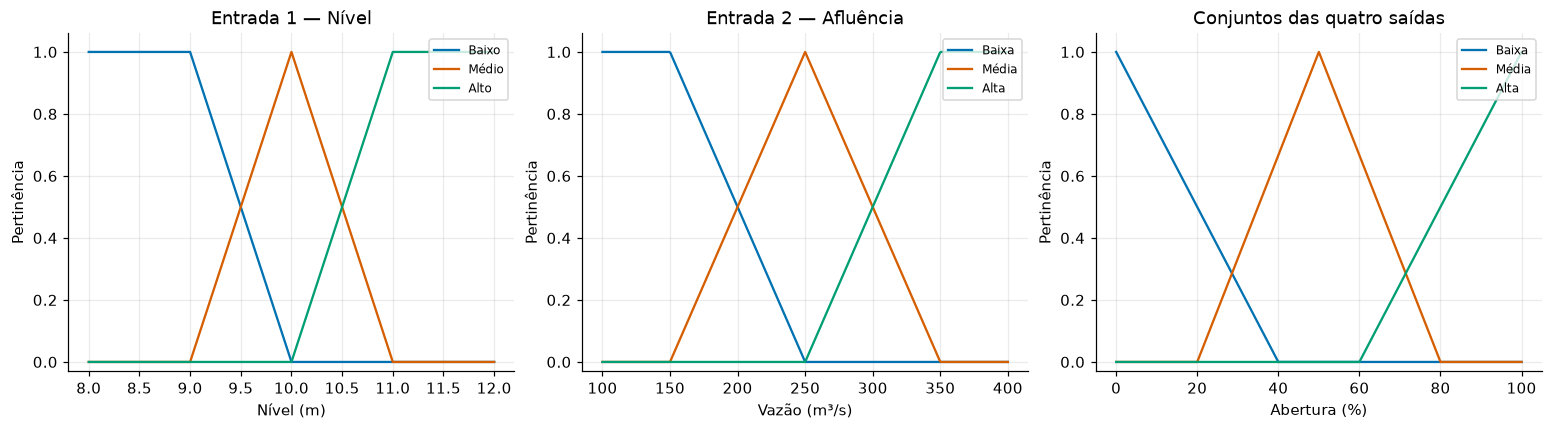

In [4]:
cores = ["#0072B2", "#D55E00", "#009E73"]
niveis = np.linspace(8, 12, 401)
vazoes = np.linspace(100, 400, 401)
grade_saida, conjuntos_saida = funcoes_saida(401)
curvas_nivel = np.array([pertinencias_entrada(h - 10) for h in niveis])
curvas_vazao = np.array([pertinencias_entrada((q - 250) / 100) for q in vazoes])
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
for j, cor in enumerate(cores):
    eixos[0].plot(niveis, curvas_nivel[:, j], color=cor, label=rotulos_nivel[j])
    eixos[1].plot(vazoes, curvas_vazao[:, j], color=cor, label=rotulos_vazao[j])
    eixos[2].plot(100 * grade_saida, conjuntos_saida[j], color=cor, label=rotulos_saida[j])
for eixo, titulo, xlabel in zip(eixos,
        ["Entrada 1 — Nível", "Entrada 2 — Afluência", "Conjuntos das quatro saídas"],
        ["Nível (m)", "Vazão (m³/s)", "Abertura (%)"]):
    eixo.set(title=titulo, xlabel=xlabel, ylabel="Pertinência", ylim=(-0.03, 1.06))
    eixo.legend(loc="upper right", fontsize=8)
plt.show()

## Teste manual das duas entradas

Altere os dois valores e execute esta célula. Os percentuais exibidos são os quatro comandos de abertura. A abertura efetiva pode demorar a alcançar esses valores por causa da dinâmica do atuador, modelada na simulação seguinte.

G1: 66.05%
G2: 54.07%
G3: 43.01%
G4: 31.81%


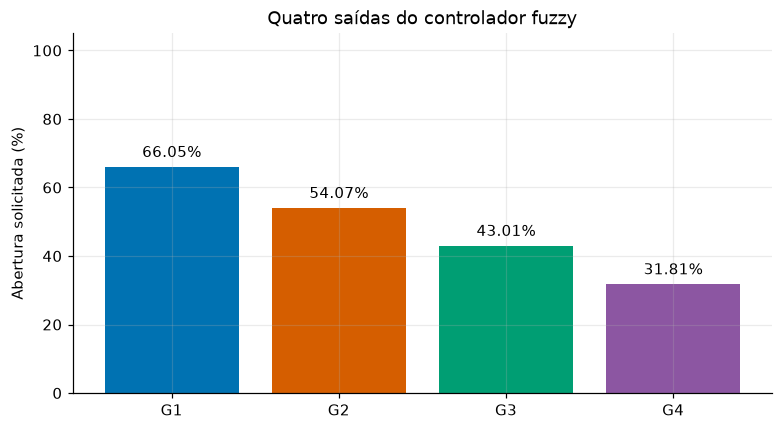

In [5]:
#@title Informe o nível e a vazão afluente
nivel_m = 9.3 #@param {type:"number"}
vazao_afluente_m3_s = 310.0 #@param {type:"number"}

saidas = controlar(nivel_m, vazao_afluente_m3_s)
for comporta, abertura_percentual in saidas.items():
    print(f"{comporta}: {abertura_percentual:.2f}%")

fig, eixo = plt.subplots(figsize=(7, 3.8), constrained_layout=True)
barras = eixo.bar(list(saidas), list(saidas.values()), color=["#0072B2", "#D55E00", "#009E73", "#8C56A2"])
eixo.bar_label(barras, labels=[f"{v:.2f}%" for v in saidas.values()], padding=4)
eixo.set(ylim=(0, 105), ylabel="Abertura solicitada (%)", title="Quatro saídas do controlador fuzzy")
plt.show()

## Simulação de 24 horas

O balanço e as quatro descargas são:

$$A\frac{dh}{dt}=Q_a-Q_t-\sum_{j=1}^{4}Q_j,\qquad Q_j=75a_j\sqrt{h/10}.$$

Cada abertura efetiva $a_j$ responde ao comando $u_j$ com constante de tempo de 120 s. A área é 100.000 m², o nível inicial é 9 m e a referência é 10 m. O controle é atualizado a cada 60 s e o modelo é integrado por Runge–Kutta de quarta ordem com passo interno de 10 s.

| Período | Afluência |
|---|---:|
| 0 a 6 h | 250 m³/s |
| 6 a 12 h | 350 m³/s |
| 12 a 18 h | 150 m³/s |
| 18 a 24 h | 250 m³/s |

O modelo de abertura controlada é idealizado; não constitui projeto de operação de uma usina. A faixa de 9 a 11 m é apenas um critério de comparação. A vazão turbinada constante não implica potência elétrica constante.

In [6]:
#@title Configuração do experimento
largura_nivel_m = 1.0 #@param {type:"number"}
ruido_sensor_m = 0.0 #@param {type:"number"}
semente = 1000 #@param {type:"integer"}

resultado = simular(largura_nivel_m=largura_nivel_m,
                    ruido_nivel_m=ruido_sensor_m, semente=semente)
referencia_fixa = simular(abertura_fixa=True)
metricas = calcular_metricas(resultado)
metricas_fixas = calcular_metricas(referencia_fixa)
print("Métricas do controlador de quatro comportas:")
print(json.dumps(metricas, indent=2, ensure_ascii=False))

Métricas do controlador de quatro comportas:
{
  "rmse_m": 0.45642823673156196,
  "mae_m": 0.3269107824035257,
  "nivel_minimo_m": 9.0,
  "nivel_maximo_m": 10.635068611866242,
  "tempo_fora_faixa_h": 0.0,
  "volume_vertido_m3": 12860000.006603746,
  "nivel_final_m": 9.999999933962416,
  "variacao_total_comando_por_comporta": {
    "G1": 1.1967225316451733,
    "G2": 2.2513199867249982,
    "G3": 2.265067453689869,
    "G4": 1.8560128272943934
  },
  "variacao_total_abertura_por_comporta": {
    "G1": 1.1868282905163026,
    "G2": 2.0671523205486397,
    "G3": 2.069214175066643,
    "G4": 1.6700543775598953
  },
  "variacao_total_comando_soma": 7.569122799354434,
  "variacao_total_abertura_soma": 6.99324916369148,
  "residuo_balanco_m3": -1.2689270079135895e-08,
  "nivel_medio_patamar_1_m": 9.999999790033229,
  "nivel_medio_patamar_2_m": 10.635061133476903,
  "nivel_medio_patamar_3_m": 9.226280906961792,
  "nivel_medio_patamar_4_m": 9.999999856591256
}


## Resposta do reservatório e das quatro comportas

O primeiro painel compara o nível com a referência e com a operação de abertura fixa. Os painéis seguintes distinguem as quatro saídas solicitadas das quatro aberturas efetivas. O último painel permite comparar afluência e defluência total.

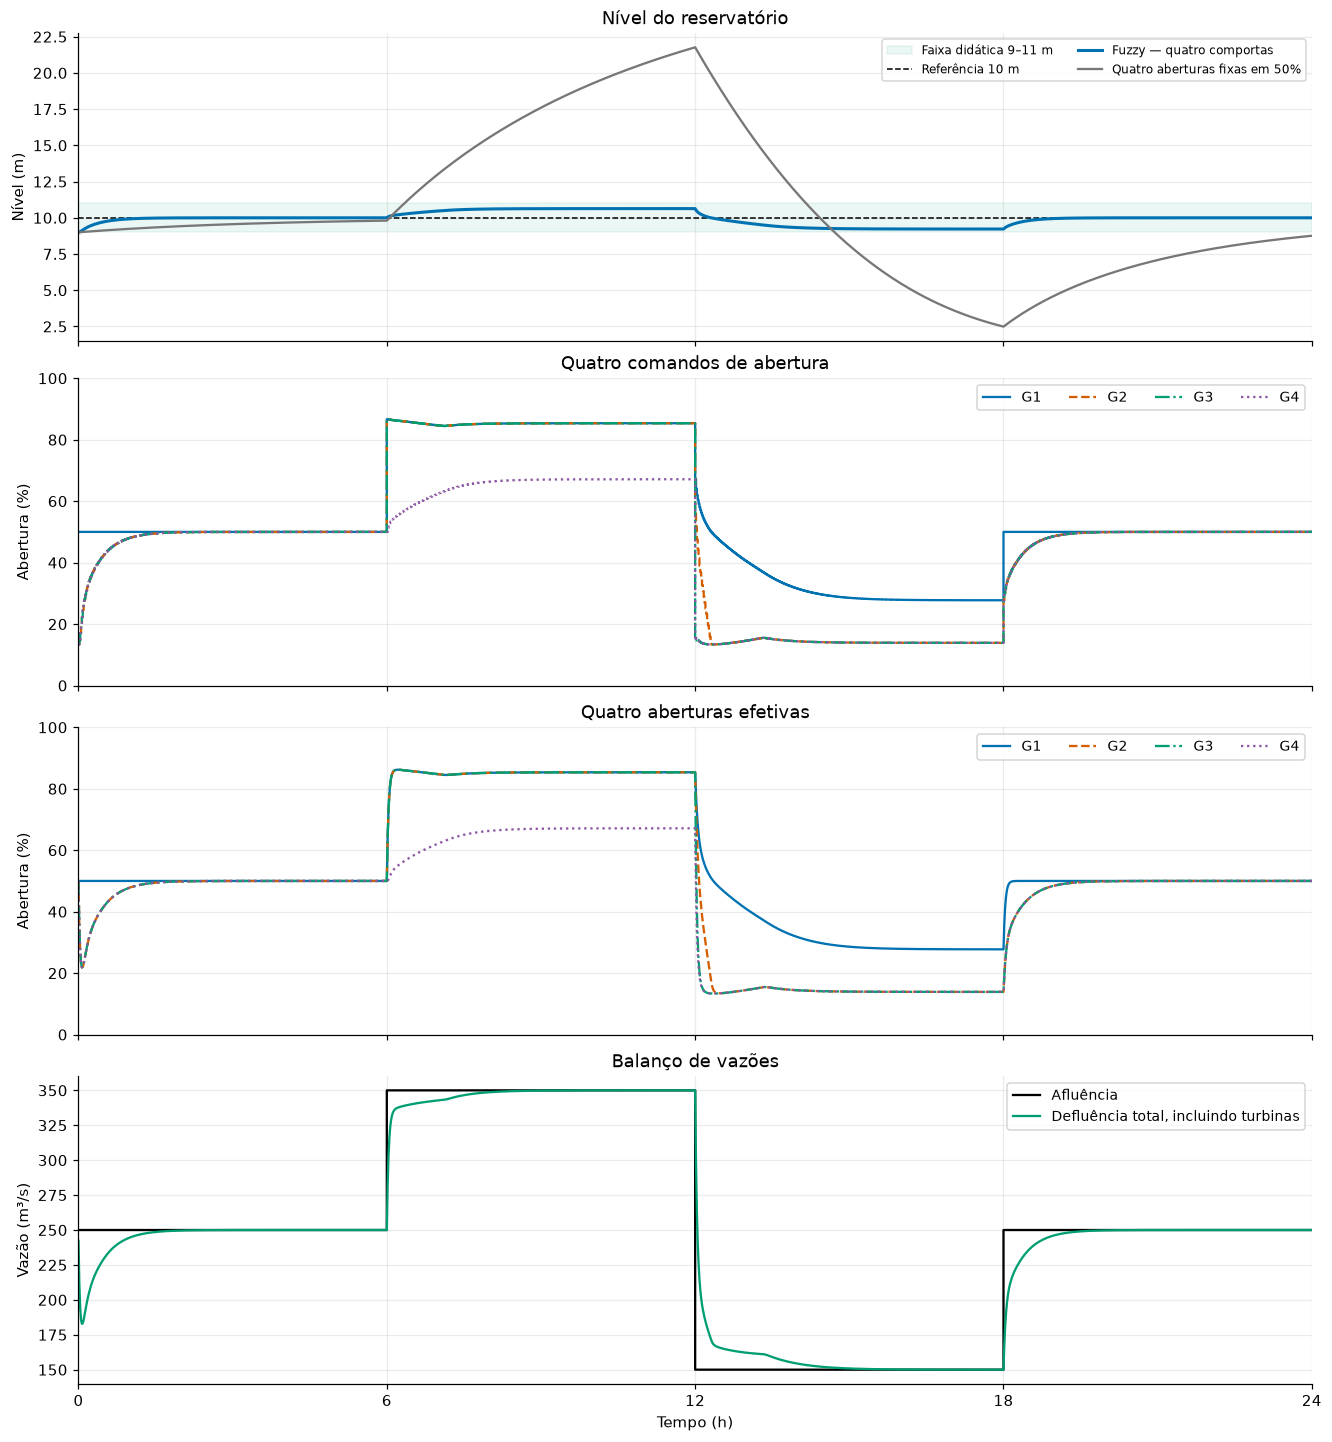

In [7]:
horas = resultado["tempo_s"] / 3600
cores_comportas = ["#0072B2", "#D55E00", "#009E73", "#8C56A2"]
estilos_comportas = ["-", "--", "-.", ":"]
fig, eixos = plt.subplots(4, 1, figsize=(12, 13), sharex=True, constrained_layout=True)
eixos[0].axhspan(9, 11, color="#009E73", alpha=0.08, label="Faixa didática 9–11 m")
eixos[0].axhline(10, color="black", ls="--", lw=1, label="Referência 10 m")
eixos[0].plot(horas, resultado["nivel_m"], color="#0072B2", lw=2, label="Fuzzy — quatro comportas")
eixos[0].plot(horas, referencia_fixa["nivel_m"], color="#777777", label="Quatro aberturas fixas em 50%")
eixos[0].set(ylabel="Nível (m)", title="Nível do reservatório")
eixos[0].legend(loc="upper right", ncol=2, fontsize=8)
for j, (comporta, cor) in enumerate(zip(COMPORTAS, cores_comportas)):
    eixos[1].step(horas, 100 * resultado["comando"][:, j], where="post", label=comporta, color=cor, linestyle=estilos_comportas[j])
    eixos[2].plot(horas, 100 * resultado["abertura"][:, j], label=comporta, color=cor, linestyle=estilos_comportas[j])
for eixo, titulo in [(eixos[1], "Quatro comandos de abertura"), (eixos[2], "Quatro aberturas efetivas")]:
    eixo.set(ylabel="Abertura (%)", ylim=(0, 100), title=titulo)
    eixo.legend(ncol=4, fontsize=9)
eixos[3].step(horas, resultado["vazao_afluente_m3_s"], where="post", color="black", label="Afluência")
vazao_defluente = 100 + np.sum(resultado["vazao_comportas_m3_s"], axis=1)
eixos[3].plot(horas, vazao_defluente, color="#009E73", label="Defluência total, incluindo turbinas")
eixos[3].set(ylabel="Vazão (m³/s)", xlabel="Tempo (h)", title="Balanço de vazões", xlim=(0, 24))
eixos[3].legend(fontsize=9)
for eixo in eixos:
    eixo.set_xticks([0, 6, 12, 18, 24])
fig.savefig("resposta_4_comportas.png", dpi=180)
plt.show()

## Verificações numéricas

Esta célula verifica a cobertura das regras, as quatro saídas, os limites físicos, o ponto de equilíbrio, o balanço de volume e o efeito de reduzir o passo de integração. As verificações não equivalem a validação de uma barragem real.

In [8]:
verificacoes = executar_verificacoes()
refinado = simular(largura_nivel_m=largura_nivel_m,
                  passo_integracao_s=5.0, ruido_nivel_m=ruido_sensor_m,
                  semente=semente)
erro_refinamento = float(np.max(np.abs(resultado["nivel_m"] - refinado["nivel_m"])))
verificacoes["refinamento_max_diferenca_nivel_m"] = erro_refinamento
verificacoes["residuo_balanco_m3"] = float(resultado["residuo_balanco_m3"])
assert erro_refinamento < 1e-4
print(json.dumps(verificacoes, indent=2, ensure_ascii=False))
assert resultado["comando"].shape[1] == 4
assert resultado["abertura"].shape[1] == 4
assert np.all((resultado["comando"] >= 0) & (resultado["comando"] <= 1))
assert abs(resultado["residuo_balanco_m3"]) < 1e-4
print("As duas entradas e as quatro saídas foram verificadas.")

{
  "status": "aprovado",
  "pares_inferencia_testados": 441,
  "nominal_percentual": {
    "G1": 50.000000000000014,
    "G2": 50.000000000000014,
    "G3": 50.000000000000014,
    "G4": 50.000000000000014
  },
  "exemplo_saidas_distintas_percentual": {
    "G1": 86.66718750000003,
    "G2": 86.66718750000003,
    "G3": 13.332812500000003,
    "G4": 13.332812500000003
  },
  "exemplo_quatro_saidas_distintas_percentual": {
    "G1": 66.0488528325607,
    "G2": 54.06948616390655,
    "G3": 43.013723201321106,
    "G4": 31.810804673446512
  },
  "capacidade_total_confirmada_m3_s_em_10m": 300,
  "compatibilidade_integracao_numpy": "trapezoid quando disponível; trapz no NumPy 1.26",
  "refinamento_max_diferenca_nivel_m": 2.3484201250312253e-08,
  "residuo_balanco_m3": -1.2689270079135895e-08
}
As duas entradas e as quatro saídas foram verificadas.


## Exportação e download

Os arquivos incluem uma coluna para cada comando e cada abertura, além das vazões por comporta. Os CSV usam ponto decimal e vírgula como delimitador. O ZIP pode ser baixado pela área de arquivos do Colab; para abrir o download automaticamente, marque a opção abaixo e execute a célula.

In [9]:
#@title Exportar os resultados
baixar_zip = False #@param {type:"boolean"}

import shutil
diretorio_resultados = Path("resultados_4_comportas")
arquivos = exportar_resultado(resultado, diretorio_resultados, prefixo="fuzzy_4_comportas")
exportar_resultado(referencia_fixa, diretorio_resultados, prefixo="abertura_fixa")
(diretorio_resultados / "verificacoes.json").write_text(
    json.dumps(verificacoes, indent=2, ensure_ascii=False), encoding="utf-8")
shutil.copyfile("resposta_4_comportas.png", diretorio_resultados / "resposta_4_comportas.png")
caminho_zip = shutil.make_archive("resultados_4_comportas", "zip", root_dir=diretorio_resultados)
print("Resultados exportados para:", diretorio_resultados)
print("Arquivo ZIP:", Path(caminho_zip).name)
if baixar_zip:
    try:
        from google.colab import files
    except ImportError:
        from IPython.display import FileLink
        display(FileLink(caminho_zip))
    else:
        files.download(caminho_zip)

Resultados exportados para: resultados_4_comportas
Arquivo ZIP: resultados_4_comportas.zip


## Como interpretar e modificar

- A função `controlar(nivel_m, vazao_m3_s)` é a interface mais simples para obter as quatro saídas em porcentagem.
- `BASE_REGRAS[i, j, k]` indica o consequente da comporta `k` para o nível `i` e a afluência `j`. Os índices 0, 1 e 2 significam baixa, média e alta.
- A capacidade total continua em 300 m³/s a 10 m, dividida igualmente entre as quatro comportas. Não multiplique a descarga total por quatro novamente.
- As regras priorizam algumas comportas; igualdade de comandos em certos estados é legítima. Comandos diferentes não significam controladores independentes do reservatório: todos utilizam as mesmas duas medidas.
- Uma largura menor aumenta a sensibilidade ao nível e ao ruído. Mudanças de regras ou parâmetros exigem nova execução e comparação das métricas.
- A planta é hipotética, com descarga idealizada e turbinamento fixo. Não há identificação de usina, otimização de geração ou garantia de segurança operacional.

**Referências de apoio:** [Zadeh, 1965](https://doi.org/10.1016/S0019-9958(65)90241-X); [Mamdani e Assilian, 1975](https://doi.org/10.1016/S0020-7373(75)80002-2); [centroide e outros métodos](https://www.mathworks.com/help/fuzzy/defuzzification-methods.html); [balanço de reservatórios](https://www.hec.usace.army.mil/confluence/hmsdocs/hmstrm/reservoir-modeling/reservoir-modeling-concepts-and-equations).